In [1]:
# Librerías

import pandas as pd

In [2]:
# Carga del dataset

path = '/home/tito/repositorios/Curso-NumPy-Pandas-Matplotlib/Online_Retail.csv'
df = pd.read_csv(path, encoding='latin1')

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [5]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df.info()

/tmp/ipykernel_2621/40610843.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  str           
 1   StockCode    541909 non-null  str           
 2   Description  540455 non-null  str           
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 33.1 MB


In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(5268)

In [8]:
unique_values = {column: df[column].unique() for column in df.columns}

for column, values in unique_values.items():
    print(f'Columna: {column}')
    print(f'Número de valores únicos: {len(values)}')
    print(f'Valores únicos: {values[:10]}')
    print('-' * 50)

Columna: InvoiceNo
Número de valores únicos: 25900
Valores únicos: <StringArray>
['536365', '536366', '536367', '536368', '536369', '536370', '536371',
 '536372', '536373', '536374']
Length: 10, dtype: str
--------------------------------------------------
Columna: StockCode
Número de valores únicos: 4070
Valores únicos: <StringArray>
['85123A',  '71053', '84406B', '84029G', '84029E',  '22752',  '21730',
  '22633',  '22632',  '84879']
Length: 10, dtype: str
--------------------------------------------------
Columna: Description
Número de valores únicos: 4224
Valores únicos: <StringArray>
[ 'WHITE HANGING HEART T-LIGHT HOLDER',                 'WHITE METAL LANTERN',
      'CREAM CUPID HEARTS COAT HANGER', 'KNITTED UNION FLAG HOT WATER BOTTLE',
      'RED WOOLLY HOTTIE WHITE HEART.',        'SET 7 BABUSHKA NESTING BOXES',
   'GLASS STAR FROSTED T-LIGHT HOLDER',              'HAND WARMER UNION JACK',
           'HAND WARMER RED POLKA DOT',       'ASSORTED COLOUR BIRD ORNAMENT']
Length: 10

In [9]:
df['Country'].nunique()

38

In [10]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [11]:
df['Description'] = df['Description'].fillna('')
df = df.dropna(subset=['CustomerID'])
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [12]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [13]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']
df.head(1)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.3


In [14]:
df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df.head(1)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,Year,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.3,2010,12


In [17]:
sales_by_year = df.groupby('Year')['TotalAmount'].sum()
sales_by_year

Year
2010     552372.860
2011    7726146.564
Name: TotalAmount, dtype: float64

In [19]:
df['Semester'] = df['Month'].apply(lambda x:1 if x<=6 else 2)

In [20]:
sales_by_semester = df.groupby(['Year', 'Semester'])['TotalAmount'].sum()
sales_by_semester

Year  Semester
2010  2            552372.860
2011  1           3166939.041
      2           4559207.523
Name: TotalAmount, dtype: float64

# Práctica

In [ ]:
# Generar las ventas por trimestre y por mes

def asignar_trimestre(mes):
    if mes <= 3:
        return 1
    elif mes <=6:
        return 2
    elif mes <= 9:
        return 3
    else:
        return 4

In [29]:
df['Quarter'] = df['Month'].apply(asignar_trimestre)

sales_by_quarter = df.groupby(['Year','Quarter'])['TotalAmount'].sum()
sales_by_quarter

Year  Quarter
2010  4           552372.860
2011  1          1487842.180
      2          1679096.861
      3          2117546.643
      4          2441660.880
Name: TotalAmount, dtype: float64

In [30]:
sales_by_month = df.groupby(['Year','Month'])['TotalAmount'].sum()
sales_by_month

Year  Month
2010  12        552372.860
2011  1         473731.900
      2         435534.070
      3         578576.210
      4         425222.671
      5         647011.670
      6         606862.520
      7         573112.321
      8         615078.090
      9         929356.232
      10        973306.380
      11       1126815.070
      12        341539.430
Name: TotalAmount, dtype: float64

**Fin práctica**

In [40]:
total_real_sales = df[df['Quantity'] > 0].shape[0]
total_real_sales

392732

In [41]:
total_returns = df[df['Quantity'] < 0].shape[0]
total_returns

8872

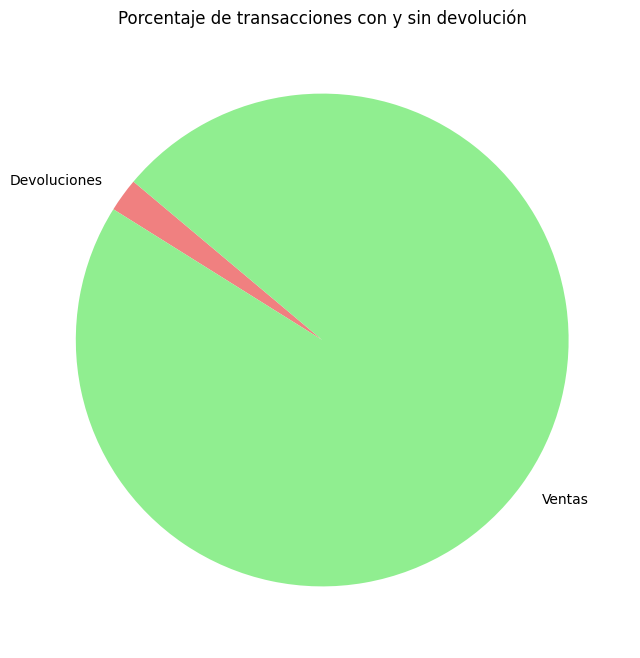

In [42]:
import matplotlib.pyplot as plt

labels = ['Devoluciones', 'Ventas']
sizes = [total_returns, total_real_sales]
colors = ['lightcoral', 'lightgreen']

plt.figure(figsize = (8,8))
plt.pie(sizes, labels= labels, colors= colors, startangle=140)
plt.title('Porcentaje de transacciones con y sin devolución')
plt.show()

In [53]:
# Categorizo el monto total

def categorize_total_amount(amount):
    if amount < 20:
        return 'Low'
    elif 20 <= amount < 100:
        return 'Medium'
    else:
        return 'High'

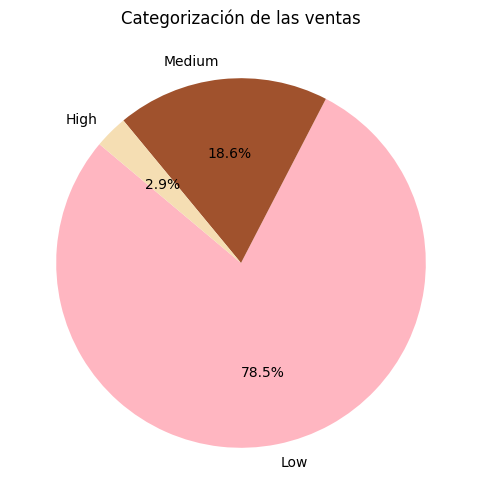

In [72]:
df['AmountCategory'] = df['TotalAmount'].apply(categorize_total_amount)
category_count = df['AmountCategory'].value_counts()

sizes = category_count.values
labels = category_count.index
colors = ['lightpink','sienna','wheat']

plt.figure(figsize=(8,6))
plt.pie(sizes, labels= labels, colors= colors, autopct='%1.1f%%', startangle=140)
plt.title('Categorización de las ventas')
plt.show() 

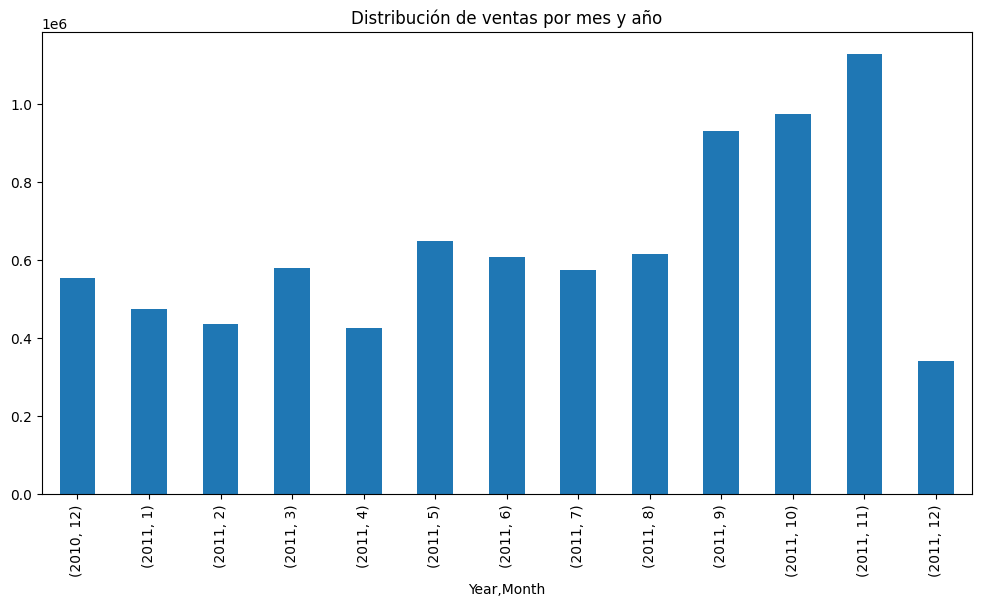

In [81]:
import numpy as np

plt.figure(figsize=(12,6))
df.groupby(['Year','Month'])['TotalAmount'].sum().plot(kind='bar')
plt.title('Distribución de ventas por mes y año')
plt.show()

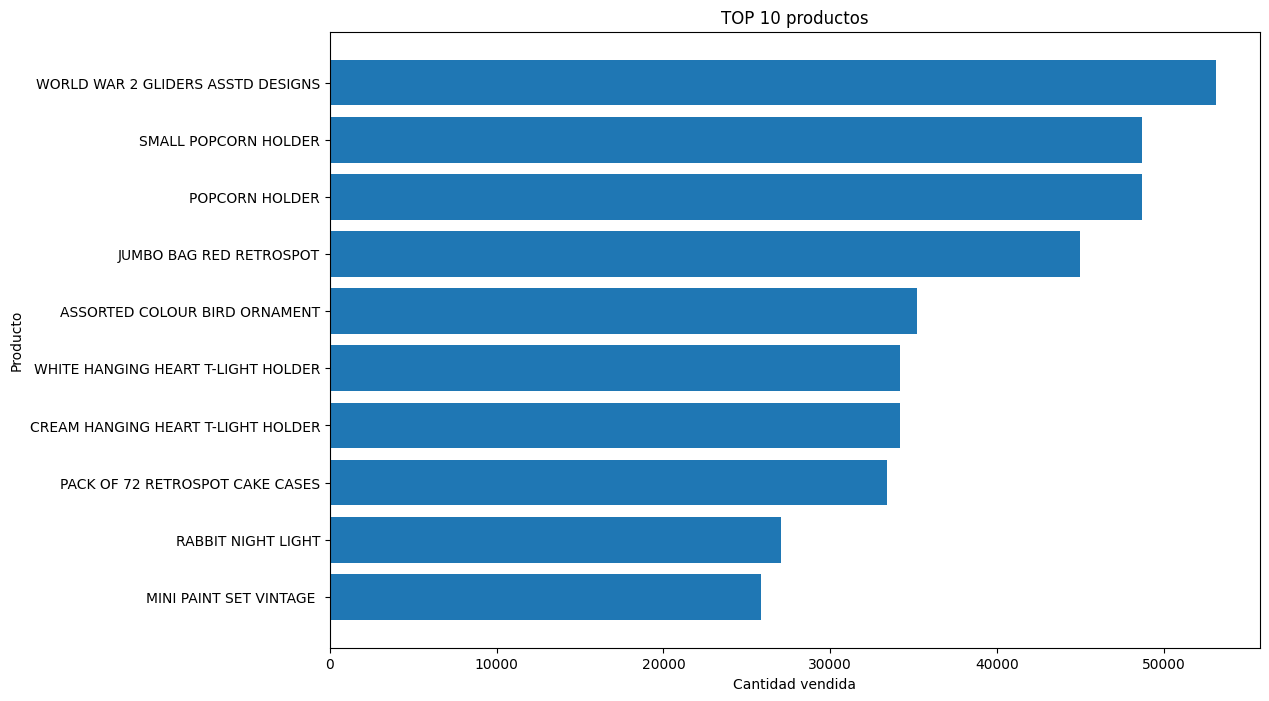

In [100]:
top10_products = df.groupby('StockCode')['Quantity'].sum().sort_values(ascending=False)
top10_products = top10_products.reset_index()
top10_products = pd.merge(top10_products, df[['StockCode', 'Description']].drop_duplicates(),
                           on='StockCode', how='left').head(10)
top10_products

plt.figure(figsize=(12,8))
plt.barh(top10_products['Description'], top10_products['Quantity'])
plt.title('TOP 10 productos')
plt.xlabel('Cantidad vendida')
plt.ylabel('Producto')
plt.gca().invert_yaxis()